Початкова матриця:
 [[  0  40  80 120 160 200]
 [ 20  60 100 140 180 220]
 [ 30  70 110 150 190 230]
 [ 50  90 130 170 210 250]]
Змінена матриця:
 [[  0  40  80 120 160 200]
 [ 20  60 100 140   0 220]
 [ 30  70 110 150 190 230]
 [ 50  90 130 170 210 250]]
Форма: (4, 6)
Тип елементів: uint8
Кількість пікселів: 24
Обсяг даних пікселів: 24 байтів


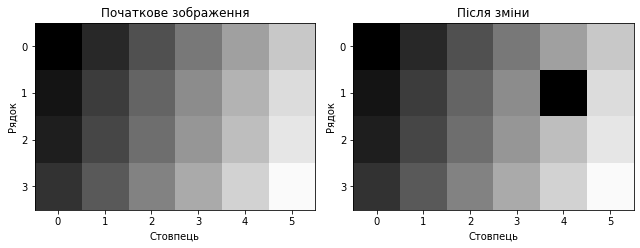

In [4]:
import numpy as np
import matplotlib.pyplot as plt

# Початкове зображення: кожне число задає яскравість одного пікселя.
G = np.array([
    [ 0, 40,  80, 120, 160, 200],
    [20, 60, 100, 140, 180, 220],
    [30, 70, 110, 150, 190, 230],
    [50, 90, 130, 170, 210, 250]
], dtype=np.uint8)

# Змінюйте ці параметри. Використовуйте цілі числа.
row = 1
col = 4
value = 0

if not (0 <= row < G.shape[0] and 0 <= col < G.shape[1]):
    raise ValueError("Індекс виходить за межі матриці")

if not 0 <= value <= 255:
    raise ValueError("Яскравість має бути від 0 до 255")

# Копія дозволяє порівнювати результат із незміненим оригіналом.
changed = G.copy()
changed[row, col] = value

print("Початкова матриця:\n", G)
print("Змінена матриця:\n", changed)
print("Форма:", G.shape)
print("Тип елементів:", G.dtype)
print("Кількість пікселів:", G.size)
print("Обсяг даних пікселів:", G.nbytes, "байтів")

fig, axes = plt.subplots(1, 2, figsize=(9, 4))

for ax, data, title in zip(
    axes,
    [G, changed],
    ["Початкове зображення", "Після зміни"]
):
    ax.imshow(
        data,
        cmap="gray",
        vmin=0,
        vmax=255,
        interpolation="nearest",
        origin="upper"
    )
    ax.set_xticks(range(data.shape[1]))
    ax.set_yticks(range(data.shape[0]))
    ax.set_xlabel("Стовпець")
    ax.set_ylabel("Рядок")
    ax.set_title(title)

plt.tight_layout()
plt.show()

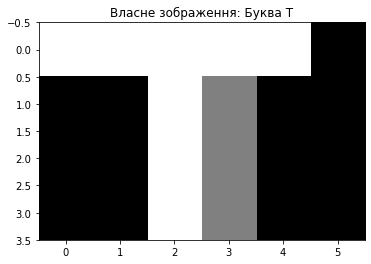

In [5]:
import numpy as np
import matplotlib.pyplot as plt

# Власне зображення (Буква "Т" з тінню)
G_custom = np.array([
    [255, 255, 255, 255, 255,   0],
    [  0,   0, 255, 128,   0,   0],
    [  0,   0, 255, 128,   0,   0],
    [  0,   0, 255, 128,   0,   0]
], dtype=np.uint8)

# Відображення малюнка
plt.imshow(G_custom, cmap="gray", vmin=0, vmax=255, interpolation="nearest")
plt.title("Власне зображення: Буква Т")
plt.show()

# Пояснення відповідності:
# 1. G_custom[0, 2] = 255. Це верхня горизонтальна лінія букви "Т".
#    Індекс 0 означає верхній рядок, індекс 2 - третій стовпець. Значення 255 робить його білим.
# 2. G_custom[2, 3] = 128. Це сіра тінь праворуч від вертикальної ніжки букви "Т".
#    Індекс 2 - це третій рядок зверху, індекс 3 - четвертий стовпець.

Підготовка: Прогноз
Найтемніший піксель: Значення 0 (абсолютно чорний). Він знаходиться на самому початку першого рядка. Індекси: row = 0, col = 0.

Найсвітліший піксель: Значення 250 (майже білий). Він знаходиться в самому кінці останнього рядка. Індекси: row = 3, col = 5.

### Таблиця результатів

| Дослід | Рядок `row` | Стовпець `col` | Початкове значення `G[row, col]` | Нове значення `value` | Прогноз | Що спостерігали |
| :--- | :---: | :---: | :---: | :---: | :--- | :--- |
| Яскравість: 0 | 1 | 4 | 180 | 0 | Піксель стане повністю чорним. | Піксель у 2-му рядку і 5-му стовпці став чорним (найтемнішим). |
| Яскравість: 64 | 1 | 4 | 180 | 64 | Піксель стане значно темнішим, темно-сірим. | Піксель став темно-сірим, помітно темнішим за оригінал (180). |
| Яскравість: 128 | 1 | 4 | 180 | 128 | Піксель стане середньо-сірим, трохи темнішим. | Піксель став сірим, світлішим за 64, але темнішим за оригінал. |
| Яскравість: 192 | 1 | 4 | 180 | 192 | Піксель стане ледь світлішим за початкове 180. | Піксель став трохи світлішим, майже не відрізняється від оригіналу. |
| Яскравість: 255 | 1 | 4 | 180 | 255 | Піксель стане абсолютно білим (найсвітлішим). | Піксель став яскраво-білим, виділяється на фоні інших. |
| Перестановка: перший | 1 | 3 | 140 | 255 | Зміниться піксель у 2-му рядку, 4-му стовпці (білий). | Білий квадрат з'явився у верхній половині ближче до центру. |
| Перестановка: другий | 3 | 1 | 90 | 255 | Зміниться піксель у 4-му рядку, 2-му стовпці (білий). | Білий квадрат з'явився внизу ліворуч, координати змінилися. |
| Верхній лівий кут | 0 | 0 | 0 | 128 | Зміниться найперший піксель (був 0). | Лівий верхній кут став сірим замість чорного. |
| Верхній правий кут | 0 | 5 | 200 | 128 | Зміниться останній піксель першого рядка. | Правий верхній кут став темнішим (сірим). |
| Нижній лівий кут | 3 | 0 | 50 | 128 | Зміниться перший піксель останнього рядка. | Лівий нижній кут став світлішим. |
| Нижній правий кут | 3 | 5 | 250 | 128 | Зміниться останній піксель (був найсвітлішим). | Правий нижній кут став помітно темнішим. |

### Масштаб відображення

| `figsize` | `G.shape` | `G.size` | `G.nbytes`, байтів | Що змінилося на екрані |
| :--- | :--- | :---: | :---: | :--- |
| `(9, 4)` | `(4, 6)` | 24 | 24 | Зображення має стандартний розмір, заданий за замовчуванням. |
| `(12, 6)` | `(4, 6)` | 24 | 24 | Самі картинки (графіки) стали візуально більшими, але матриця не змінилася. |

Питання до результатів
1)Що визначає значення елемента матриці, а що — його індекси? Поясніть на одному зі своїх експериментів.
Значення елемента визначає його яскравість (колір пікселя від 0 до 255). Індекси [row, col] визначають просторове розташування (координати) цього пікселя на зображенні. Наприклад, в експерименті зі зміною яскравості [1, 4], індекси залишалися незмінними (той самий піксель), але зміна значення з 0 до 255 змінювала його колір з чорного на білий.

2)Чому G[1, 3] і G[3, 1] змінюють різні пікселі? Який індекс відповідає горизонтальному положенню на нашому зображенні?
Індекси матриці не симетричні: перший індекс row (рядок) відповідає за вертикальне положення (згори вниз), а другий col (стовпець) — за горизонтальне (зліва направо). Тому G[1, 3] — це 2-й рядок і 4-й стовпець, а G[3, 1] — це 4-й рядок і 2-й стовпець (абсолютно різні координати). Горизонтальному положенню відповідає другий індекс — стовпець col.

3)Чи змінилися кількість пікселів і обсяг їхніх даних після збільшення figsize? Підтвердьте відповідь результатами другої таблиці.
Ні, не змінилися. Згідно з таблицею результатів, G.shape залишився (4, 6), size — 24, а nbytes — 24. Параметр figsize впливає лише на розмір візуалізації графіка на екрані, але ніяк не модифікує самі дані матриці в пам'яті комп'ютера.

4)Чому на екрані видно великі квадрати, хоча кожному відповідає один піксель нашої матриці?
Наша матриця дуже маленька (всього 24 пікселя: 4x6). Щоб ми могли їх побачити на великому графіку, функція imshow розтягує це зображення. Оскільки в коді встановлено параметр interpolation="nearest", алгоритм не згладжує переходи між пікселями, а просто збільшує кожен одиничний піксель матриці до розміру великого квадрата на екрані.

Висновок
У ході виконання роботи було практично доведено, що цифрове чорно-біле зображення є двовимірною матрицею, де кожен елемент є окремим пікселем. Індекси матриці (рядок та стовпець) жорстко задають координати пікселя (вертикаль та горизонталь відповідно), тоді як числове значення у клітинці визначає рівень його яскравості (від 0 до 255). Також експериментально підтверджено, що візуальний масштаб відображення графіка на екрані впливає лише на розмір картинки, але ніяк не змінює фізичний розмір та обсяг даних самої матриці в оперативній пам'яті комп'ютера.